# Biomedical Image Analysis · Your project, end to end
### Template notebook · Sessions 13–15 · Thursday 19.11.2026

Prof. Dr. Judith Cerit · SRH University Munich

**How to use it.** Change **only the cell "YOUR DATA"** below. Then run the parts one after the other.
Every part saves what your report needs into the folder `results/`.
In class I run each part first on the demo data (DermaMNIST, skin spots); then you run it on your data.

| Part | Session | What it does | Files in `results/` | Report section |
|---|---|---|---|---|
| A · Data | 13 | look, count, the floor, twins, patients, data table | `A1`–`A4` | 1, 2 |
| B · Models | 14 | a simple baseline, a borrowed network, heat maps | `B1`–`B5` | 3, 6 |
| C · Evaluation | 15 | 3 seeds, an interval, calibration, worst cases | `C1`–`C5` | 4, 5 |

Colab: **Runtime → Change runtime type → T4 GPU** before you start.
Segmentation project (masks)? Use Part A here, and the U-Net cells of the Session 9 notebook for B and C (Dice instead of accuracy).

**Our project: Kvasir-SEG, polyp segmentation (masks).** As the note above says, we use
**Part A** of this template. Labels are masks, not classes, so A2 counts the share of polyp
pixels and the floor is a Dice score instead of an accuracy. A1, A3 (twins, same method and
limit as the template), A4 and A5 keep the template's steps and file names.
Parts B and C come from the U-Net cells of the Session 9 notebook (Dice instead of accuracy).

In [1]:
# ============ YOUR DATA: change only this cell ============
QUESTION = "Can a U-Net outline polyps in colonoscopy images well enough to help a doctor not miss one, and how much better is it than a simple colour threshold?"
DATA     = "kvasir-seg"   # Kvasir-SEG (Jha et al., MMM 2020): 1,000 colonoscopy images, one polyp mask each
SIZE     = 256            # images and masks are shrunk to SIZE x SIZE
FOLDER   = None           # not used: scripts/download_data.py fetches the data into data/
FOCUS    = "polyp"        # the "class" of every mask pixel we care about
PATIENT_ID = None         # Kvasir-SEG file names are random IDs: no patient information
# ===========================================================

## Setup: load the data (our version: images + masks, our split)

In [2]:
import os, sys, numpy as np, matplotlib.pyplot as plt, torch
import torch.nn.functional as F
from pathlib import Path
if "google.colab" in sys.modules and not os.path.exists("src"):
    !git clone https://github.com/Chandana18G/kvasir-seg-polyp-segmentation
    %cd kvasir-seg-polyp-segmentation
if os.path.basename(os.getcwd()) in ("chandana", "dinesh"):
    os.chdir("..")
if not os.path.exists("data/Kvasir-SEG/images"):
    !python scripts/download_data.py
if not os.path.exists("splits/train.txt"):
    !python scripts/make_split.py
sys.path.insert(0, "src")
from data import load_resized, read_split

R = Path("results"); R.mkdir(exist_ok=True)
X, M, NAMES = {}, {}, {}
for s in ("train", "val", "test"):
    NAMES[s] = read_split(s)
    pairs = [load_resized(n, SIZE) for n in NAMES[s]]
    X[s] = np.stack([p[0] for p in pairs])       # images: (n, SIZE, SIZE, 3)
    M[s] = np.stack([p[1] for p in pairs])       # masks:  (n, SIZE, SIZE), 1 = polyp
    print(f"{s:5s} {len(X[s]):6d} images of {SIZE} x {SIZE} pixels (shrunk from 332-1920 px wide)")

train    779 images of 256 x 256 pixels (shrunk from 332-1920 px wide)


val      100 images of 256 x 256 pixels (shrunk from 332-1920 px wide)


test     120 images of 256 x 256 pixels (shrunk from 332-1920 px wide)


---
# Part A · Data (Session 13) → report sections 1 and 2
## A1 · Look at 20 images, with their labels

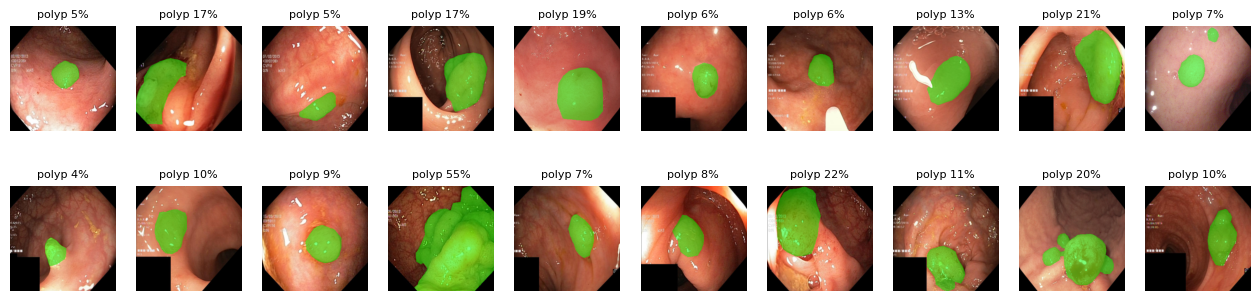

In [3]:
rng = np.random.default_rng(1)
pick = rng.choice(len(X["train"]), 20, replace=False)
fig, axes = plt.subplots(2, 10, figsize=(16, 3.8))
for ax, i in zip(axes.ravel(), pick):
    img = X["train"][i].copy(); m = M["train"][i] == 1
    img[m] = (0.5 * img[m] + [0, 127, 0]).astype(np.uint8)        # polyp in green
    ax.imshow(img); ax.set_title(f"polyp {M['train'][i].mean():.0%}", fontsize=8); ax.axis("off")
fig.savefig(R / "A1_examples.png", dpi=150, bbox_inches="tight"); plt.show()

## A2 · Count: share of polyp pixels, and the floor (Dice instead of accuracy)

In [4]:
def dice(pred, truth):
    s = pred.sum() + truth.sum()
    return 2 * (pred * truth).sum() / s if s > 0 else 1.0
share = {s: M[s].reshape(len(M[s]), -1).mean(1) for s in M}
lines = ["split,images,mean_polyp_share,median_polyp_share,images_under_5_percent"]
for s in share:
    lines.append(f"{s},{len(share[s])},{share[s].mean():.4f},{np.median(share[s]):.4f},{int((share[s] < 0.05).sum())}")
    print(f"{s:5s} {len(share[s]):4d} images   polyp share mean {share[s].mean():.1%}, median {np.median(share[s]):.1%}, "
          f"{int((share[s] < 0.05).sum())} images under 5 %")
(R / "A2_counts.csv").write_text("\n".join(lines))
floor_bg = np.mean([dice(np.zeros_like(m), m) for m in M["test"]])
floor_all = [dice(np.ones_like(m), m) for m in M["test"]]
floor = float(np.mean(floor_all))
print(f"\nThe floor on the test images: always 'background' -> Dice {floor_bg:.3f}; "
      f"always 'polyp' -> Dice {floor:.3f} ± {np.std(floor_all):.3f}")

train  779 images   polyp share mean 15.4%, median 11.2%, 151 images under 5 %
val    100 images   polyp share mean 15.3%, median 12.3%, 20 images under 5 %
test   120 images   polyp share mean 15.3%, median 11.7%, 29 images under 5 %

The floor on the test images: always 'background' -> Dice 0.000; always 'polyp' -> Dice 0.243 ± 0.184


## A3 · Twins: is (almost) the same image in training and in test?
For every test image: its most similar training image (mean pixel difference, at 64 × 64).

In [5]:
def small(x):
    t = torch.tensor(x, dtype=torch.float32).permute(0, 3, 1, 2) / 255
    return F.interpolate(t, size=(64, 64), mode="bilinear", antialias=True).reshape(len(t), -1)
tr, te = small(X["train"]), small(X["test"])
dist, nearest = torch.cat([torch.cdist(te[i:i + 500], tr) for i in range(0, len(te), 500)]).div(tr.shape[1] ** 0.5).min(1)
twins = (dist < 0.03).nonzero().ravel()
print(f"{len(twins)} of {len(te)} test images have an almost identical training image (difference < 0.03).")
order = twins[dist[twins].argsort()][:6]
if len(order):
    fig, axes = plt.subplots(2, len(order), figsize=(2 * len(order), 4.2), squeeze=False)
    for k, t in enumerate(order):
        axes[0, k].imshow(X["test"][t]); axes[0, k].set_title("test", fontsize=9)
        axes[1, k].imshow(X["train"][nearest[t]]); axes[1, k].set_title("training", fontsize=9)
    for a in axes.ravel(): a.axis("off")
    fig.savefig(R / "A3_twins.png", dpi=150, bbox_inches="tight"); plt.show()

0 of 120 test images have an almost identical training image (difference < 0.03).


## A4 · Patients: is the same patient in training and in test?
Only possible if the file names (or a table) tell the patient. MedMNIST does not: then write that in the report.

In [6]:
# Kvasir-SEG file names are random IDs (e.g. cju0qkwl35piu0993l0dewei2): no patient.
# What we did instead (scripts/make_split.py): image fingerprint + mask overlap found 7
# near-duplicate pairs; the one training copy of a test image was removed.
patient_line = ("patient not known from the files: cannot check; near-duplicate check found 7 pairs, "
                "1 training copy of a test image removed (scripts/make_split.py)")
print(patient_line)

patient not known from the files: cannot check; near-duplicate check found 7 pairs, 1 training copy of a test image removed (scripts/make_split.py)


## A5 · The data table (report, section 2)
The numbers are filled in for you. Complete the lines with `…` by hand in `results/A5_data_table.md`.

In [7]:
n_all = sum(len(X[s]) for s in X)
table = f"""| | |
|---|---|
| Question | {QUESTION} |
| Source, licence | Kvasir-SEG, https://datasets.simula.no/kvasir-seg/ (Jha et al., MMM 2020); research and education only, cite the paper; images not in our repository |
| Modality, size | Endoscopy (colonoscopy), 2D RGB frames; {n_all} images (+ 1 dropped as a copy of a test image), 332-1920 px wide, used at {SIZE} × {SIZE} pixels; pixel size not reported |
| Labels | one mask per image: polyp / background; who decided them: an engineer and a medical doctor (Labelbox), checked by one gastroenterologist; agreement not reported |
| Classes | polyp pixels: mean {share['train'].mean():.0%} of a training image (median {np.median(share['train']):.0%}); every image has a polyp; floor: always background Dice {floor_bg:.3f}, always polyp Dice {floor:.3f} |
| Splits | {len(X['train'])} / {len(X['val'])} / {len(X['test'])} (training / validation / test); test = the authors' 120; not by patient |
| Quality checks | {len(twins)} of {len(te)} test images have a near-twin in training (template check); {patient_line} |
| Where my data could differ | site: one hospital group in Norway (Vestre Viken) · device: Olympus endoscopes · population: Norwegian routine colonoscopies · who labelled: one team, one reviewer |
| A possible shortcut | black corner box, date/time text, black border; 13 test images (0 training) still show the coloured position box; 23 test images come from a later batch |
"""
(R / "A5_data_table.md").write_text(table); print(table)

| | |
|---|---|
| Question | Can a U-Net outline polyps in colonoscopy images well enough to help a doctor not miss one, and how much better is it than a simple colour threshold? |
| Source, licence | Kvasir-SEG, https://datasets.simula.no/kvasir-seg/ (Jha et al., MMM 2020); research and education only, cite the paper; images not in our repository |
| Modality, size | Endoscopy (colonoscopy), 2D RGB frames; 999 images (+ 1 dropped as a copy of a test image), 332-1920 px wide, used at 256 × 256 pixels; pixel size not reported |
| Labels | one mask per image: polyp / background; who decided them: an engineer and a medical doctor (Labelbox), checked by one gastroenterologist; agreement not reported |
| Classes | polyp pixels: mean 15% of a training image (median 11%); every image has a polyp; floor: always background Dice 0.000, always polyp Dice 0.243 |
| Splits | 779 / 100 / 120 (training / validation / test); test = the authors' 120; not by patient |
| Quality checks | 0 of 120 test im

### Before you go on: push Part A
GitHub: your repository → **Add file → Upload files** → the `results/` folder.
Then in Colab: **File → Save a copy in GitHub** (the notebook with its outputs).